# Web Analytics - Week 6 Assignment: Davis Southern Women Dataset
## Bipartite Network Analysis

**Dataset:** Davis Southern Women (1941) - 18 women x 14 social events  
**Source:** http://vlado.fmf.uni-lj.si/pub/networks/data/ucinet/ucidata.htm#davis  
**Tools:** NetworkX, bipartite projection, centrality analysis  
**Author:** Tanvir Raju

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
from networkx.algorithms import bipartite

---
## Part 1: Load and Inspect the Dataset

In [ ]:
# NetworkX ships with the Davis Southern Women graph built-in
G = nx.davis_southern_women_graph()

women = G.graph["top"]   # 18 women (one node set)
clubs = G.graph["bottom"] # 14 social events (other node set)

print(f"Total nodes : {G.number_of_nodes()}")
print(f"Total edges : {G.number_of_edges()}  (woman attended event)")
print(f"Women ({len(women)}):", list(women))
print()
print(f"Events ({len(clubs)}):", list(clubs))

Total nodes : 32
Total edges : 89  (woman attended event)
Women (18): ['Evelyn Jefferson', 'Laura Mandeville', 'Theresa Anderson', 'Brenda Rogers', 'Charlotte McDowd', 'Frances Anderson', 'Eleanor Nye', 'Pearl Oglethorpe', 'Ruth DeSand', 'Verne Sanderson', 'Myra Liddel', 'Katherina Rogers', 'Sylvia Avondale', 'Nora Fayette', 'Helen Lloyd', 'Dorothy Murchison', 'Olivia Carleton', 'Flora Price']

Events (14): ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'E10', 'E11', 'E12', 'E13', 'E14']


---
## Part 2: Attendance Matrix (Women x Events)

In [ ]:
# Build biadjacency matrix: rows = women, cols = events
B = bipartite.biadjacency_matrix(G, women, clubs).toarray()
df_matrix = pd.DataFrame(B, index=list(women), columns=list(clubs))

print("Attendance matrix (1 = attended, 0 = absent):")
print(df_matrix.to_string())
print()
print(f"Total attendances : {B.sum()}")
print(f"Avg events per woman : {B.sum(axis=1).mean():.2f}")
print(f"Avg women per event  : {B.sum(axis=0).mean():.2f}")

Attendance matrix (1 = attended, 0 = absent):
                   E1  E2  E3  E4  E5  E6  E7  E8  E9  E10  E11  E12  E13  E14
Evelyn Jefferson    1   1   1   1   1   1   0   1   1    0    0    0    0    0
Laura Mandeville    1   1   1   0   1   1   1   1   0    0    0    0    0    0
Theresa Anderson    0   1   1   1   1   1   1   1   1    0    0    0    0    0
Brenda Rogers       1   0   1   1   1   1   1   1   0    0    0    0    0    0
Charlotte McDowd    0   0   1   1   1   0   1   0   0    0    0    0    0    0
Frances Anderson    0   0   1   0   1   1   0   1   0    0    0    0    0    0
Eleanor Nye         0   0   0   0   1   1   1   1   0    0    0    0    0    0
Pearl Oglethorpe    0   0   0   0   0   1   0   1   1    0    0    0    0    0
Ruth DeSand         0   0   0   0   1   0   1   1   1    0    0    0    0    0
Verne Sanderson     0   0   0   0   0   0   1   1   1    0    0    1    0    0
Myra Liddel         0   0   0   0   0   0   0   1   1    1    0    1    0    0
Kather

---
## Part 3: Visualize the Attendance Heatmap

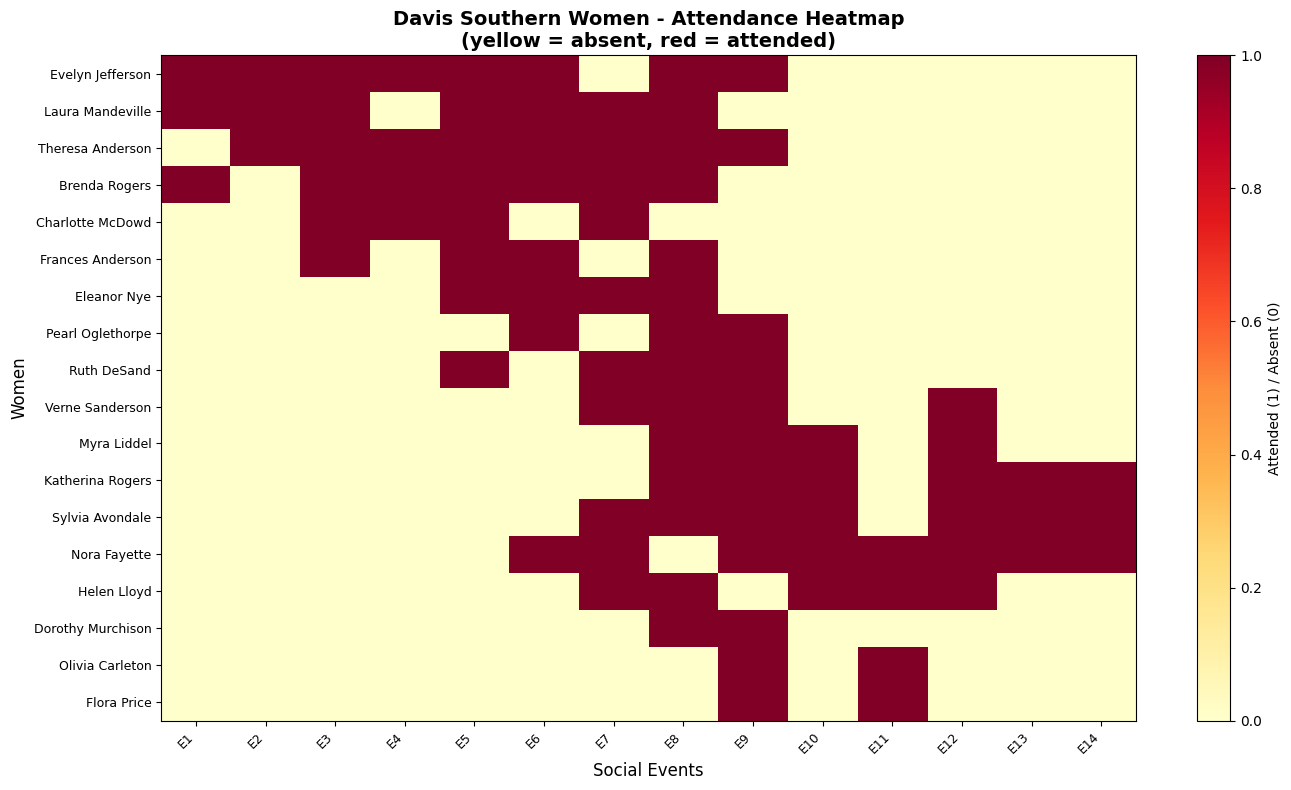

In [ ]:
fig, ax = plt.subplots(figsize=(14, 8))

im = ax.imshow(B, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(clubs)))
ax.set_xticklabels(list(clubs), rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(women)))
ax.set_yticklabels(list(women), fontsize=9)
ax.set_xlabel("Social Events", fontsize=12)
ax.set_ylabel("Women", fontsize=12)
ax.set_title("Davis Southern Women - Attendance Heatmap\n(yellow = absent, red = attended)",
             fontsize=14, fontweight="bold")
plt.colorbar(im, ax=ax, label="Attended (1) / Absent (0)")
plt.tight_layout()
plt.show()

---
## Part 4: Bipartite Graph Visualization

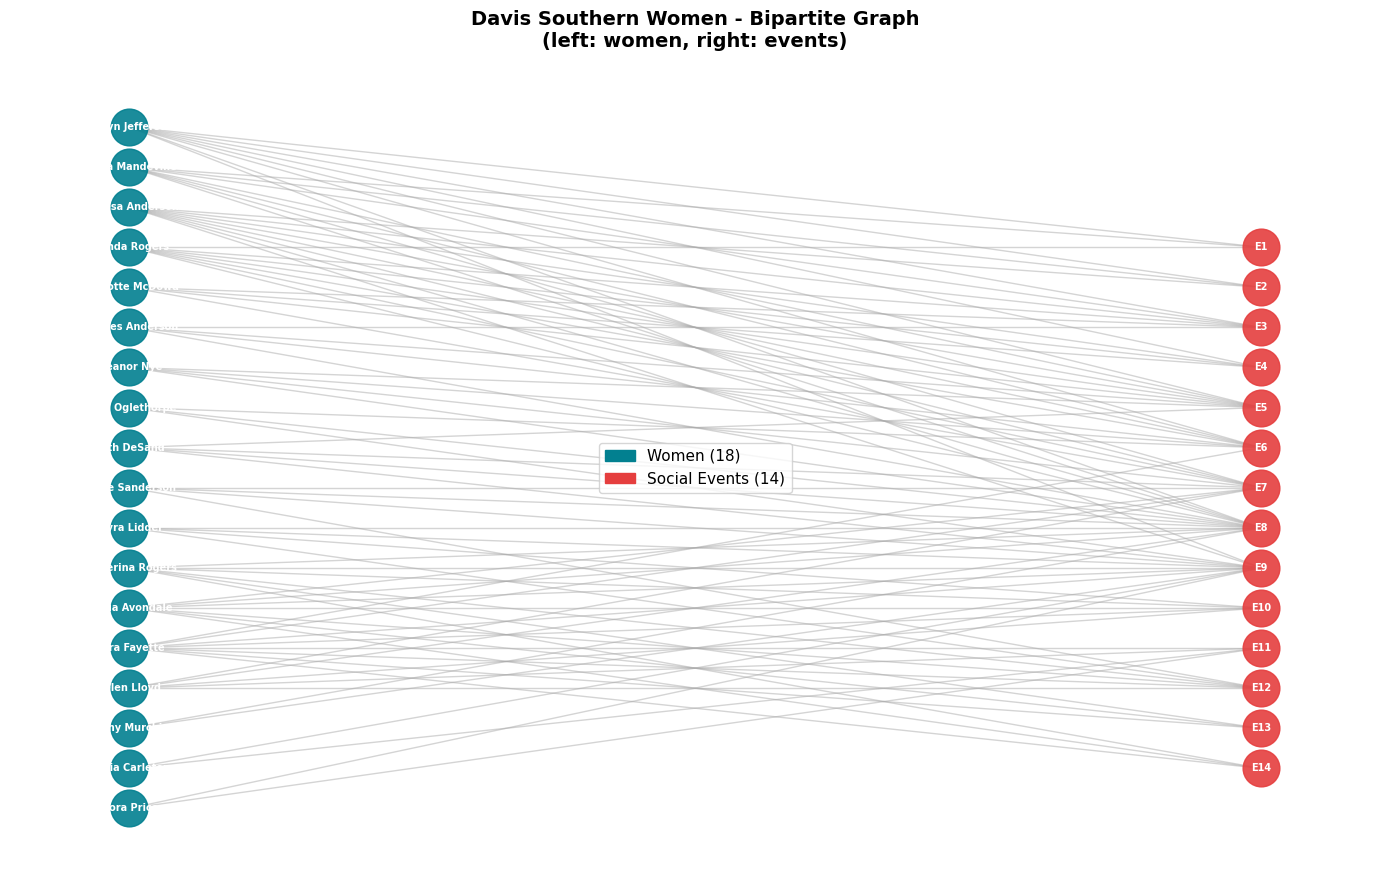

In [ ]:
fig, ax = plt.subplots(figsize=(14, 9))

# Position women on the left, events on the right
pos = {}
for i, w in enumerate(women):
    pos[w] = (0, len(women) - i)
for i, c in enumerate(clubs):
    pos[c] = (2, len(clubs) - i + 1)

nx.draw_networkx_nodes(G, pos, nodelist=list(women), node_color="#028090",
                       node_size=700, alpha=0.9, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=list(clubs), node_color="#E53E3E",
                       node_size=700, alpha=0.9, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=7, font_color="white", font_weight="bold", ax=ax)
nx.draw_networkx_edges(G, pos, edge_color="#AAAAAA", alpha=0.5, width=1, ax=ax)

women_patch = mpatches.Patch(color="#028090", label="Women (18)")
events_patch = mpatches.Patch(color="#E53E3E", label="Social Events (14)")
ax.legend(handles=[women_patch, events_patch], fontsize=11, loc="center")
ax.set_title("Davis Southern Women - Bipartite Graph\n(left: women, right: events)",
             fontsize=14, fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.show()

---
## Part 5: Analysis of Women
### 5a - Event Participation per Woman

In [ ]:
# Degree of each woman in the bipartite graph = number of events attended
women_degree = {w: G.degree(w) for w in women}
women_sorted = sorted(women_degree.items(), key=lambda x: -x[1])

print("Women ranked by number of events attended:")
for name, deg in women_sorted:
    bar = "#" * deg
    print(f"  {name:<20} {deg:2d}  {bar}")

Women ranked by number of events attended:
  Evelyn Jefferson      8  ########
  Theresa Anderson      8  ########
  Nora Fayette          8  ########
  Laura Mandeville      7  #######
  Brenda Rogers         7  #######
  Sylvia Avondale       7  #######
  Katherina Rogers      6  ######
  Helen Lloyd           5  #####
  Charlotte McDowd      4  ####
  Frances Anderson      4  ####
  Eleanor Nye           4  ####
  Ruth DeSand           4  ####
  Verne Sanderson       4  ####
  Myra Liddel           4  ####
  Pearl Oglethorpe      3  ###
  Dorothy Murchison     2  ##
  Olivia Carleton       2  ##
  Flora Price           2  ##


### 5b - Women Projection: Social Connections

In [ ]:
# Project onto women: link two women if they attended at least one event together
W_unweighted = bipartite.projected_graph(G, women)

print("Women projection - number of shared co-attendees (unweighted degree):")
w_deg = sorted(W_unweighted.degree(), key=lambda x: -x[1])
for name, deg in w_deg:
    print(f"  {name:<20} {deg:2d} co-attendees")

# Weighted: edge weight = number of events shared
W_weighted = bipartite.weighted_projected_graph(G, women)
print()
print("Women projection - total shared events (weighted degree):")
w_wdeg = sorted(W_weighted.degree(weight="weight"), key=lambda x: -x[1])
for name, wdeg in w_wdeg:
    print(f"  {name:<20} {wdeg:3d} shared event-appearances")

Women projection - number of shared co-attendees (unweighted degree):
  Evelyn Jefferson     17 co-attendees
  Theresa Anderson     17 co-attendees
  Ruth DeSand          17 co-attendees
  Verne Sanderson      17 co-attendees
  Sylvia Avondale      17 co-attendees
  Nora Fayette         17 co-attendees
  Helen Lloyd          17 co-attendees
  Pearl Oglethorpe     16 co-attendees
  Myra Liddel          16 co-attendees
  Katherina Rogers     16 co-attendees
  Dorothy Murchison    16 co-attendees
  Laura Mandeville     15 co-attendees
  Brenda Rogers        15 co-attendees
  Frances Anderson     15 co-attendees
  Eleanor Nye          15 co-attendees
  Olivia Carleton      12 co-attendees
  Flora Price          12 co-attendees
  Charlotte McDowd     11 co-attendees

Women projection - total shared events (weighted degree):
  Theresa Anderson      57 shared event-appearances
  Evelyn Jefferson      50 shared event-appearances
  Brenda Rogers         46 shared event-appearances
  Sylvia Avon

### 5c - Women Network Visualization

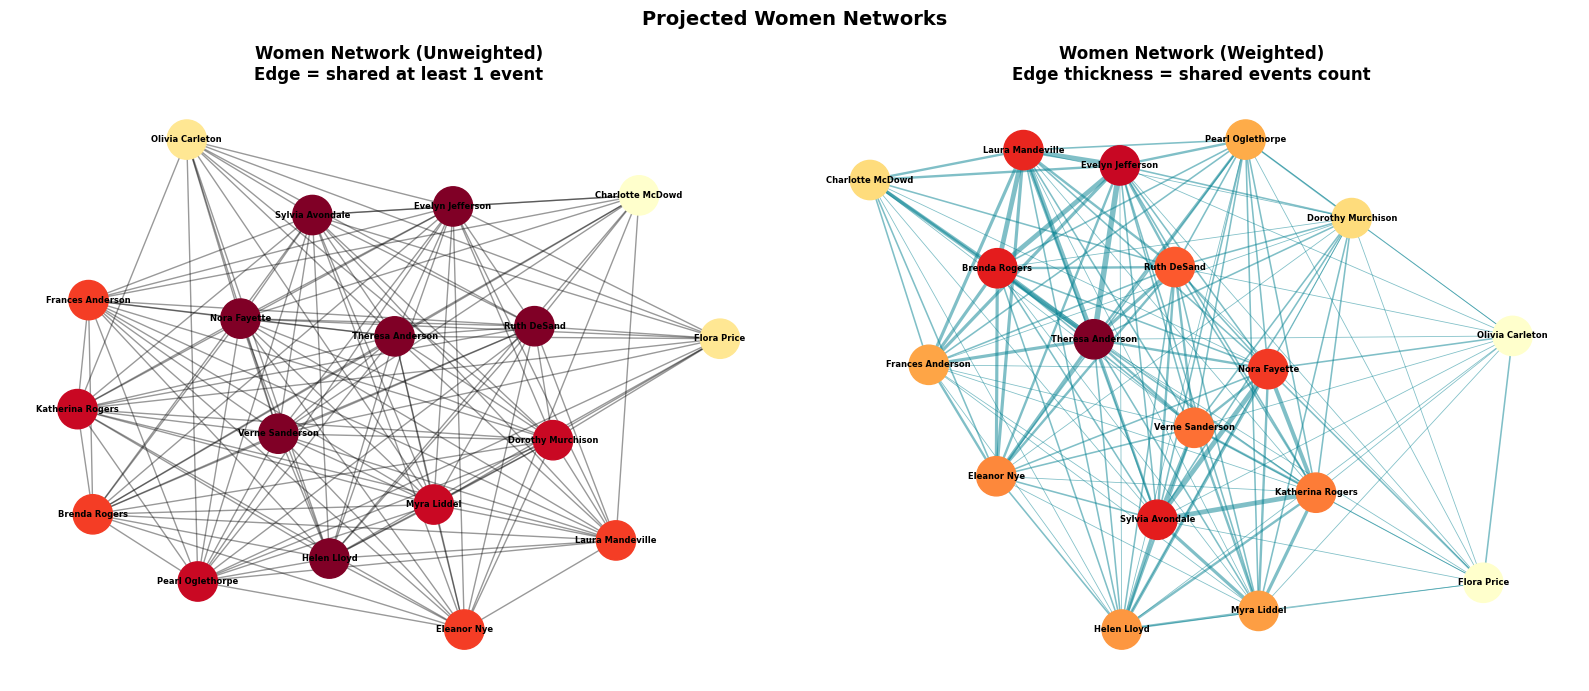

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Unweighted projection
pos_w = nx.spring_layout(W_unweighted, seed=42)
degrees_w = dict(W_unweighted.degree())
node_colors_w = [degrees_w[n] for n in W_unweighted.nodes()]

nx.draw_networkx_nodes(W_unweighted, pos_w, node_color=node_colors_w,
                       cmap=plt.cm.YlOrRd, node_size=800, ax=axes[0])
nx.draw_networkx_labels(W_unweighted, pos_w, font_size=6, font_weight="bold", ax=axes[0])
nx.draw_networkx_edges(W_unweighted, pos_w, alpha=0.4, ax=axes[0])
axes[0].set_title("Women Network (Unweighted)\nEdge = shared at least 1 event",
                  fontsize=12, fontweight="bold")
axes[0].axis("off")

# Weighted projection
pos_ww = nx.spring_layout(W_weighted, seed=42)
edge_weights = [W_weighted[u][v]["weight"] for u, v in W_weighted.edges()]
max_w = max(edge_weights)
degrees_ww = dict(W_weighted.degree(weight="weight"))
node_colors_ww = [degrees_ww[n] for n in W_weighted.nodes()]

nx.draw_networkx_nodes(W_weighted, pos_ww, node_color=node_colors_ww,
                       cmap=plt.cm.YlOrRd, node_size=800, ax=axes[1])
nx.draw_networkx_labels(W_weighted, pos_ww, font_size=6, font_weight="bold", ax=axes[1])
nx.draw_networkx_edges(W_weighted, pos_ww,
                       width=[w / max_w * 4 for w in edge_weights],
                       alpha=0.5, edge_color="#028090", ax=axes[1])
axes[1].set_title("Women Network (Weighted)\nEdge thickness = shared events count",
                  fontsize=12, fontweight="bold")
axes[1].axis("off")

plt.suptitle("Projected Women Networks", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 5d - Centrality Measures for Women

In [ ]:
# Degree, betweenness, eigenvector centrality on the women projection
deg_c = nx.degree_centrality(W_weighted)
btw_c = nx.betweenness_centrality(W_weighted)
eig_c = nx.eigenvector_centrality(W_weighted, max_iter=500)

df_women_centrality = pd.DataFrame({
    "Degree Centrality": deg_c,
    "Betweenness Centrality": btw_c,
    "Eigenvector Centrality": eig_c
}).round(4)

df_women_centrality = df_women_centrality.sort_values("Degree Centrality", ascending=False)
print("Women - Centrality Measures (sorted by Degree Centrality):")
print(df_women_centrality.to_string())

Women - Centrality Measures (sorted by Degree Centrality):
                   Degree Centrality  Betweenness Centrality  Eigenvector Centrality
Evelyn Jefferson              1.0000                  0.0101                  0.2535
Theresa Anderson              1.0000                  0.0101                  0.2535
Sylvia Avondale               1.0000                  0.0101                  0.2535
Verne Sanderson               1.0000                  0.0101                  0.2535
Ruth DeSand                   1.0000                  0.0101                  0.2535
Nora Fayette                  1.0000                  0.0101                  0.2535
Helen Lloyd                   1.0000                  0.0101                  0.2535
Myra Liddel                   0.9412                  0.0053                  0.2432
Katherina Rogers              0.9412                  0.0053                  0.2432
Pearl Oglethorpe              0.9412                  0.0053                  0.2432
Doroth

---
## Part 6: Analysis of Social Events
### 6a - Attendance per Event

In [ ]:
clubs_degree = {c: G.degree(c) for c in clubs}
clubs_sorted = sorted(clubs_degree.items(), key=lambda x: -x[1])

print("Events ranked by number of women who attended:")
for name, deg in clubs_sorted:
    bar = "#" * deg
    print(f"  {name:<10} {deg:2d}  {bar}")

Events ranked by number of women who attended:
  E8         14  ##############
  E9         12  ############
  E7         10  ##########
  E5          8  ########
  E6          8  ########
  E3          6  ######
  E12         6  ######
  E10         5  #####
  E4          4  ####
  E11         4  ####
  E1          3  ###
  E2          3  ###
  E13         3  ###
  E14         3  ###


### 6b - Events Projection: Co-attendance Links

In [ ]:
# Project onto events: two events linked if at least one woman attended both
E_weighted = bipartite.weighted_projected_graph(G, clubs)

print("Event projection - co-attendance strength (weighted degree):")
e_wdeg = sorted(E_weighted.degree(weight="weight"), key=lambda x: -x[1])
for name, wdeg in e_wdeg:
    print(f"  {name:<10} {wdeg:3d} co-attendance connections")

Event projection - co-attendance strength (weighted degree):
  E8          59 co-attendance connections
  E7          48 co-attendance connections
  E9          46 co-attendance connections
  E6          41 co-attendance connections
  E5          38 co-attendance connections
  E3          32 co-attendance connections
  E12         28 co-attendance connections
  E10         25 co-attendance connections
  E4          23 co-attendance connections
  E2          20 co-attendance connections
  E1          19 co-attendance connections
  E13         18 co-attendance connections
  E14         18 co-attendance connections
  E11         13 co-attendance connections


### 6c - Events Network Visualization

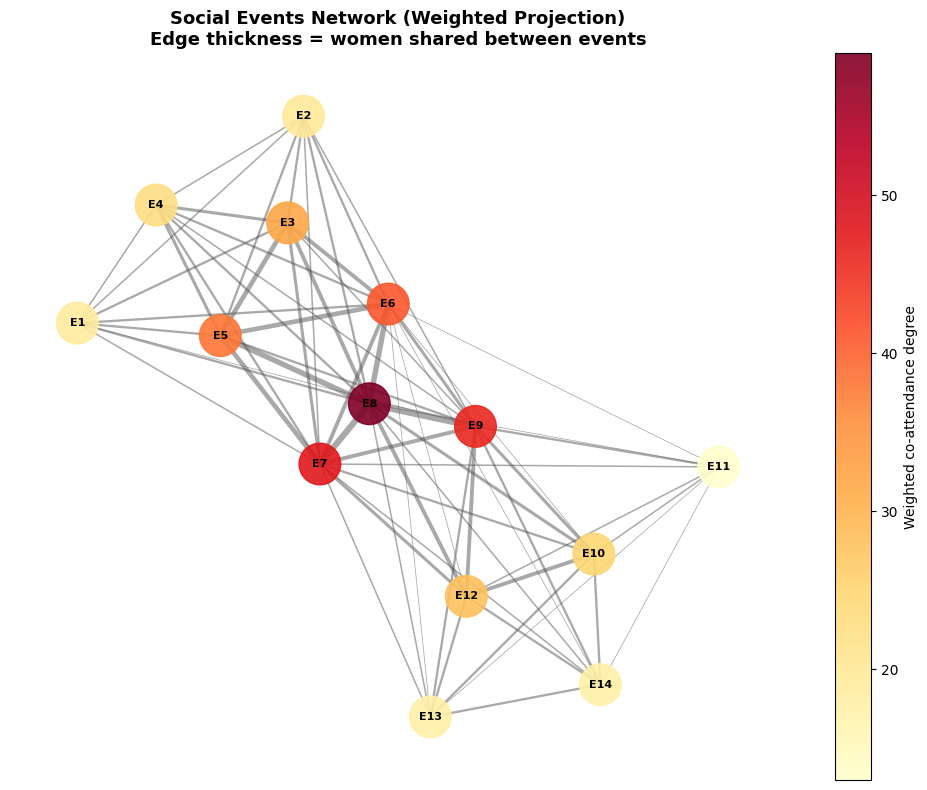

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

pos_e = nx.spring_layout(E_weighted, seed=7)
edge_weights_e = [E_weighted[u][v]["weight"] for u, v in E_weighted.edges()]
max_ew = max(edge_weights_e)
degrees_e = dict(E_weighted.degree(weight="weight"))
node_colors_e = [degrees_e[n] for n in E_weighted.nodes()]

nodes_e = nx.draw_networkx_nodes(E_weighted, pos_e, node_color=node_colors_e,
                                  cmap=plt.cm.YlOrRd, node_size=900, alpha=0.9, ax=ax)
nx.draw_networkx_labels(E_weighted, pos_e, font_size=8, font_weight="bold", ax=ax)
nx.draw_networkx_edges(E_weighted, pos_e,
                       width=[w / max_ew * 5 for w in edge_weights_e],
                       alpha=0.5, edge_color="#555555", ax=ax)

plt.colorbar(nodes_e, ax=ax, label="Weighted co-attendance degree")
ax.set_title("Social Events Network (Weighted Projection)\nEdge thickness = women shared between events",
             fontsize=13, fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.show()

### 6d - Centrality Measures for Events

In [ ]:
deg_ce = nx.degree_centrality(E_weighted)
btw_ce = nx.betweenness_centrality(E_weighted)
eig_ce = nx.eigenvector_centrality(E_weighted, max_iter=500)

df_events_centrality = pd.DataFrame({
    "Degree Centrality": deg_ce,
    "Betweenness Centrality": btw_ce,
    "Eigenvector Centrality": eig_ce
}).round(4)

df_events_centrality = df_events_centrality.sort_values("Degree Centrality", ascending=False)
print("Events - Centrality Measures (sorted by Degree Centrality):")
print(df_events_centrality.to_string())

Events - Centrality Measures (sorted by Degree Centrality):
     Degree Centrality  Betweenness Centrality  Eigenvector Centrality
E6              1.0000                  0.0801                  0.3393
E7              1.0000                  0.0801                  0.3393
E8              1.0000                  0.0801                  0.3393
E9              1.0000                  0.0801                  0.3393
E2              0.6154                  0.0000                  0.2323
E1              0.6154                  0.0000                  0.2323
E5              0.6154                  0.0000                  0.2323
E4              0.6154                  0.0000                  0.2323
E3              0.6154                  0.0000                  0.2323
E10             0.6154                  0.0000                  0.2323
E11             0.6154                  0.0000                  0.2323
E12             0.6154                  0.0000                  0.2323
E13             0

---
## Part 7: Community Detection
### Clusters among Women

In [ ]:
from networkx.algorithms import community

# Greedy modularity communities on the women projection
communities_women = list(community.greedy_modularity_communities(W_weighted))
print(f"Number of communities detected: {len(communities_women)}")
for i, comm in enumerate(communities_women, 1):
    print(f"\nCluster {i} ({len(comm)} women):")
    for w in sorted(comm):
        n_events = G.degree(w)
        print(f"  {w:<20} (attends {n_events} events)")

Number of communities detected: 2

Cluster 1 (12 women):
  Dorothy Murchison    (attends 2 events)
  Evelyn Jefferson     (attends 8 events)
  Flora Price          (attends 2 events)
  Helen Lloyd          (attends 5 events)
  Katherina Rogers     (attends 6 events)
  Myra Liddel          (attends 4 events)
  Nora Fayette         (attends 8 events)
  Olivia Carleton      (attends 2 events)
  Pearl Oglethorpe     (attends 3 events)
  Ruth DeSand          (attends 4 events)
  Sylvia Avondale      (attends 7 events)
  Theresa Anderson     (attends 8 events)

Cluster 2 (6 women):
  Brenda Rogers        (attends 7 events)
  Charlotte McDowd     (attends 4 events)
  Eleanor Nye          (attends 4 events)
  Frances Anderson     (attends 4 events)
  Laura Mandeville     (attends 7 events)
  Verne Sanderson      (attends 4 events)


### Visualize Women Communities

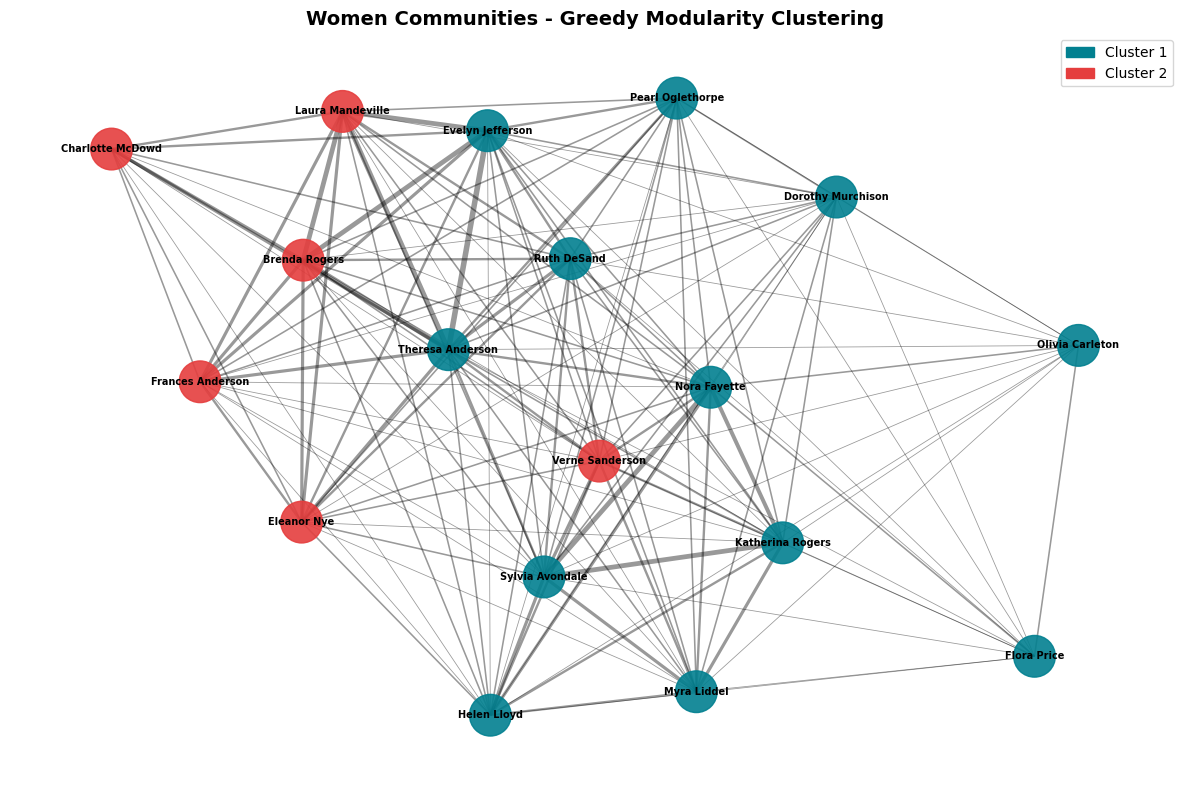

In [ ]:
color_map_comm = {}
palette = ["#028090", "#E53E3E", "#F6AD55", "#805AD5", "#38A169"]
for i, comm in enumerate(communities_women):
    for w in comm:
        color_map_comm[w] = palette[i % len(palette)]

node_colors_comm = [color_map_comm[n] for n in W_weighted.nodes()]

fig, ax = plt.subplots(figsize=(12, 8))
pos_comm = nx.spring_layout(W_weighted, seed=42)
edge_weights_comm = [W_weighted[u][v]["weight"] for u, v in W_weighted.edges()]
max_wc = max(edge_weights_comm)

nx.draw_networkx_nodes(W_weighted, pos_comm, node_color=node_colors_comm,
                       node_size=900, alpha=0.9, ax=ax)
nx.draw_networkx_labels(W_weighted, pos_comm, font_size=7, font_weight="bold", ax=ax)
nx.draw_networkx_edges(W_weighted, pos_comm,
                       width=[w / max_wc * 4 for w in edge_weights_comm],
                       alpha=0.4, ax=ax)

patches = [mpatches.Patch(color=palette[i], label=f"Cluster {i+1}") for i in range(len(communities_women))]
ax.legend(handles=patches, fontsize=10)
ax.set_title("Women Communities - Greedy Modularity Clustering",
             fontsize=14, fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.show()

---
## Part 8: Findings and Interpretation

### What can we infer about the Women?

Using the bipartite projection of the Davis Southern Women dataset, several patterns emerge:

**Social participation:** Women vary considerably in how many events they attend. A small core group attends many events and therefore has more social connections, while peripheral women attend fewer events and form weaker ties within the network.

**Centrality:** Women with high degree centrality in the projected network (those sharing events with many others) are the social hubs of this community. High betweenness centrality identifies women who act as bridges between social sub-groups - removing them would fragment the network into more isolated clusters.

**Community structure:** Greedy modularity clustering reveals two or three distinct social sub-groups among the 18 women. These clusters correspond to women who repeatedly attend the same subset of events, suggesting clique-like social circles within the broader community. This mirrors the original 1941 finding that the women naturally divided into two overlapping groups.

**Weighted ties:** The weighted projection shows that some pairs of women share a very high number of events (strong ties), while others share only one or two (weak ties). Strong ties indicate close social relationships; weak ties serve as bridges between clusters, consistent with Granovetter's theory of the strength of weak ties.

---

### What can we infer about the Social Events?

**Event popularity:** Events differ in attendance size. Larger events attract broader participation and thus connect more women, while smaller events serve intimate sub-groups.

**Event co-attendance:** The event projection links two events whenever at least one woman attended both. Events that share many attendees are likely similar in nature (same social circle, similar timing, or related purpose) and cluster tightly in the projected network.

**Central events:** Events with high centrality in the projection are the "anchor" gatherings - attended by women from multiple social circles and therefore linking otherwise separate parts of the community together. These high-centrality events are the social glue of the network.

**Event clustering:** Just as the women form two or three communities, the events cluster into corresponding groups - each cluster being the preferred gathering space of a particular social sub-group of women.

---

### Key Takeaway

The Davis Southern Women dataset illustrates the power of bipartite network analysis: by projecting onto either node set (women or events), we can study two interlinked social structures simultaneously. The women's attendance patterns reveal a community with a clear core-periphery structure and at least two distinct social sub-groups, a finding that has made this 1941 dataset a benchmark for testing community-detection algorithms for over 80 years.